# A3: finer terrain (100 m, 300 m) and learning rate for the SFNO station correction

**Question.** A2 fed the operator 28 terrain descriptors on a 1 km grid. Do descriptors from a
finer terrain grid (100 m or 300 m) improve the correction at unseen stations? Does a lower
learning rate help?

**Setup** (same as A2):
* SFNO on the 0.25° IFS + AIFS grid, with a point-wise MLP head on the station descriptors.
  Inputs are terrain only (no obs-forecast).
* 99 northern Frost stations, 5 spatially held-out groups: each group is predicted by a model
  trained on the other 4.
* Train 2024-03 – 2024-12, validation 2025-01 – 2025-03 (best epoch), test 2025-04-01 – 2025-09-12.
* Metric: vector RMSE of (u, v), change in % against the mean of IFS and AIFS. Negative = better.
  Single seed.

**Fine terrain** (scripts/build_terrain_100m.py):
* Elevation: the Kartverket 50 m DTM over Norway and Copernicus GLO-90 elsewhere, averaged onto a
  100 m or 300 m grid on the windcast LAEA plane.
* Fields at grid spacing R:

| field | 100 m grid | 300 m grid |
|---|---|---|
| slope | slope100 | slope300 |
| elevation minus its mean within 3R (TPI) | tpi300 | tpi900 |
| std of elevation within 3R | std300 | std900 |
| steepest rise toward 8 directions within 3R and 10R (shelter) | sx300, sx1k | sx900, sx3k |

* Two ways to give them to the model, added to the 28 descriptors at 1 km:
  * **cell statistics**: mean of every field over the station's 1 km cell, plus the std of TPI
    and elevation (21 values; they exist at every 1 km cell);
  * **point and cell**: the station's own fine cell (elevation + the fields) as well as the cell
    statistics.
* The shelter angles are also used toward the forecast wind direction (upwind shelter), as in A2.


In [1]:
import json, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, '..')
from windcast.station_correction import station_groups
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
ROOT = Path('/cluster/work/projects/nn8106k/siyan/windcast'); RUNS = ROOT / 'runs_a1'
d = dict(np.load(ROOT / 'cache/multimodel_2024-03-01_2025-09-12.npz', allow_pickle=True))
inits, leads = pd.DatetimeIndex(d['inits']), list(d['leads'])
ti = pd.Index(d['time']).get_indexer(inits)
obs = np.stack([d['obs'][ti + ld] for ld in leads], 1)
base = d['st_fc'].mean(2)                               # mean of IFS and AIFS at the stations
te = (inits >= '2025-04-01') & (inits <= pd.Timestamp('2025-09-12 12:00')) & d['keep']
groups = station_groups(d['xy'].astype(float))

def change(pred):
    m = te[:, None, None] & np.isfinite(obs[..., 0]) & np.isfinite(pred[..., 0])
    r = lambda p: np.array([np.sqrt(((obs[:, j] - p[:, j]) ** 2).sum(-1)[m[:, j]].mean()) for j in range(len(leads))])
    return (r(pred) / r(base) - 1) * 100

def held_out(sfx):
    """test prediction of every station from the model that did not see its group; best epochs"""
    acc = np.full_like(base, np.nan)
    best = []
    for k in range(5):
        p = RUNS / f'sfno_terrain_g{k}_s0{sfx}'
        acc[:, :, groups == k] = np.load(p / 'pred.npz')['test'][:, :, groups == k]
        h = json.loads((p / 'history.json').read_text())['history']
        best.append(min(range(len(h)), key=lambda i: h[i]['val']))
    return change(base + acc), best

TERR = {'': '1 km only', '_c100': '+ 100 m cell stats', '_pc100': '+ 100 m point and cell',
        '_c300': '+ 300 m cell stats', '_pc300': '+ 300 m point and cell'}
LR = {'': 1e-3, '_lr0.0001': 1e-4, '_lr3e-05': 3e-5}
res, rows = {}, []
for ls, lr in LR.items():
    for ts, tn in TERR.items():
        if not (RUNS / f'sfno_terrain_g4_s0{ts}{ls}' / 'pred.npz').exists():
            continue
        r, best = held_out(ts + ls)
        res[(lr, tn)] = r
        rows.append({'lr': f'{lr:g}', 'terrain': tn, '+6 h': r[leads.index(6)], '+24 h': r[leads.index(24)],
                     '+66 h': r[leads.index(66)], 'mean': r.mean(), 'best epochs': best})
tab = pd.DataFrame(rows).set_index(['lr', 'terrain'])
tab.style.format({c: '{:.1f}' for c in ['+6 h', '+24 h', '+66 h', 'mean']})

## Results: vector RMSE change vs the IFS + AIFS mean (%), held-out stations

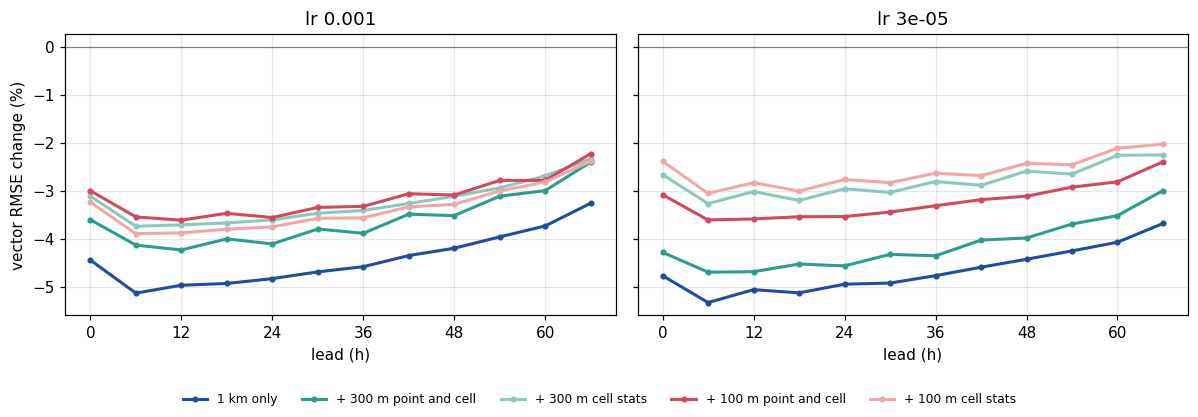

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
col = {'1 km only': '#1f4e9c', '+ 300 m point and cell': '#2a9d8f', '+ 300 m cell stats': '#8ac9bf',
       '+ 100 m point and cell': '#d1495b', '+ 100 m cell stats': '#f2a7a7'}
for a, lr in zip(ax, (1e-3, 3e-5)):
    for tn, c in col.items():
        if (lr, tn) in res:
            a.plot(leads, res[(lr, tn)], '-o', ms=3, lw=2, color=c, label=tn)
    a.axhline(0, color='0.5', lw=0.8)
    a.set(title=f'lr {lr:g}', xlabel='lead (h)', xticks=leads[::2])
ax[0].set_ylabel('vector RMSE change (%)')
fig.legend(*ax[0].get_legend_handles_labels(), loc='lower center', ncol=5, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))

In [3]:
# mean over leads (%): rows learning rate, columns terrain input
tab['mean'].unstack('terrain')[list(TERR.values())].round(1)

terrain,1 km only,+ 100 m cell stats,+ 100 m point and cell,+ 300 m cell stats,+ 300 m point and cell
lr,,,,,
0.0001,-4.3,-2.7,-2.8,NaN,NaN
0.001,-4.4,-3.4,-3.2,-3.3,-3.6
3e-05,-4.7,-2.6,-3.2,-2.8,-4.1


## Summary

* **The 1 km descriptors alone are best.** At lr 3e-5: −5.3 % at +6 h, −3.7 % at +66 h,
  −4.7 % on average (A2 at lr 1e-3: −4.4 %).
* **Finer terrain makes the held-out result worse at every learning rate.** With 100 m
  descriptors the average is −2.6 to −3.4 %. 300 m is less harmful; the best is point and cell
  at lr 3e-5, −4.1 %. The coarser the extra descriptors, the closer the result is to 1 km only.
* **The fine terrain is likely not useless; there are too few stations.** With only 99 training
  stations, each extra set of static descriptors gives the point head more ways to recognise
  individual training stations. That does not transfer to unseen stations.
* **A lower learning rate** moves the best epoch from 0–2 (lr 1e-3) to 6–13 (lr 3e-5) and helps
  the 1 km model slightly (−4.4 → −4.7 %). It does not remove the loss from the fine
  descriptors.
* Single seed: differences below about 0.5 percentage points are not reliable.

**Decision:** use the 1 km descriptors and lr 3e-5 for the next experiments (MLWP / NWP input
comparison). Revisit finer terrain when training on the ~280 stations of all of Norway.
